# Issue #377 — corrected N6 R3 support-transfer count grid

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/n6_support_transfer_grid'

In [2]:
dev=pd.read_csv(OUT/'development_diagnostic_gate.csv')
dev

,base,diagnostic,conditioning,rows,mean_score,observed_rate,bin_spearman,nonnegative_monotonicity
0,R0_CORRECTED,contraction_score,SUPPORTED_REALIZED,1219,0.713440,0.712879,0.737819,True
1,R0_CORRECTED,expansion_score,ALL,1521,0.162085,0.198554,0.745455,True
2,R3_CORRECTED,contraction_score,SUPPORTED_REALIZED,1197,0.727458,0.722640,0.709510,True
3,R3_CORRECTED,expansion_score,ALL,1521,0.181445,0.213018,0.917937,True


In [3]:
perf=pd.read_csv(OUT/'performance.csv')
perf[perf.scope.eq('ALL')]

,scope,cell,contraction_count,expansion_count,issues,ticket_count_per_issue,average_ticket_stake_cny,total_tickets,ticket_hit_rate,issue_gross_positive_rate,...,stake_cny,gross_cny,pnl_cny,ending_capital_cny,capital_return,stake_roi,conditional_gross_on_hit_cny,ex_largest_pnl_cny,ideal_fractional_pnl_cny,integer_minus_ideal_cny
45,ALL,C0E0,0,0,152,64,16.000000,9728,0.003701,0.236842,...,155648.0,143348.010358,-12299.989642,87700.010358,-0.123000,-0.079024,3981.889177,-35959.696286,-12299.989642,0.000000
46,ALL,C0E1,0,1,152,96,10.666667,14592,0.003289,0.315789,...,155648.0,117305.125135,-38342.874865,61657.125135,-0.383429,-0.246344,2443.856774,-52746.191517,-34796.558476,-3546.316389
47,ALL,C0E2,0,2,152,144,7.111111,21888,0.002924,0.421053,...,155648.0,120467.423372,-35180.576628,64819.423372,-0.351806,-0.226027,1882.303490,-43412.966620,-32814.252905,-2366.323723
48,ALL,C0E3,0,3,152,216,4.740741,32832,0.002345,0.506579,...,155648.0,102888.370642,-52759.629358,47240.370642,-0.527596,-0.338968,1336.212606,-58318.389589,-51393.558353,-1366.071005
49,ALL,C0E4,0,4,152,324,3.160494,49248,0.001868,0.605263,...,155648.0,95390.753653,-60257.246347,39742.753653,-0.602572,-0.387138,1036.856018,-65404.173008,-61549.901688,1292.655341
50,ALL,C1E0,1,0,152,32,32.000000,4864,0.005345,0.171053,...,155648.0,156308.094678,660.094678,100660.094678,0.006601,0.004241,6011.849795,-33423.959883,660.094678,0.000000
51,ALL,C1E1,1,1,152,48,21.333333,7296,0.004797,0.230263,...,155648.0,129330.365010,-26317.634990,73682.365010,-0.263176,-0.169084,3695.153286,-49430.422501,-26939.575173,621.940183
52,ALL,C1E2,1,2,152,72,14.222222,10944,0.004569,0.328947,...,155648.0,155360.371807,-287.628193,99712.371807,-0.002876,-0.001848,3107.207436,-15204.385357,611.496364,-899.124556
53,ALL,C1E3,1,3,152,108,9.481481,16416,0.003716,0.401316,...,155648.0,145026.775122,-10621.224878,89378.775122,-0.106212,-0.068239,2377.488117,-20983.479995,-10756.473282,135.248404
54,ALL,C1E4,1,4,152,162,6.320988,24624,0.002924,0.473684,...,155648.0,119572.818702,-36075.181298,63924.818702,-0.360752,-0.231774,1660.733593,-44160.185392,-34383.381181,-1691.800117


In [4]:
annual=perf[perf.scope.ne('ALL')].pivot(index='cell',columns='scope',values='pnl_cny')
annual

scope,2022,2023,2024
cell,,,
C0E0,-28545.420051,-2698.890179,18944.320588
C0E1,-22461.688546,-11729.897741,-4151.288577
C0E2,-16083.363447,-8885.182128,-10212.031053
C0E3,-27045.466386,-12305.691315,-13408.471657
C0E4,-22463.863949,-14683.884216,-23109.498183
C1E0,-25992.714718,-27400.906167,54053.715564
C1E1,-25918.870598,-26918.483919,26519.719527
C1E2,-18283.981156,-4418.303850,22414.656813
C1E3,-25287.288572,4547.285320,10118.778374


In [5]:
risk=pd.read_csv(OUT/'risk_diagnostics.csv')
runs=pd.read_csv(OUT/'losing_run_diagnostics.csv')
risk[risk.scope.eq('ALL')].merge(runs[runs.scope.eq('ALL')],on=['scope','cell'])

,scope,cell,max_drawdown_fraction,longest_profitable_issue_losing_run,open_underwater_issues,largest_payout_share,payout_hhi,losing_run_count,longest_run,median_run,p75_run,p90_run,runs_ge_10,runs_ge_15
0,ALL,C0E0,0.468927,19,152,0.172194,0.067544,25,19,2.0,9.00,11.6,4,2
1,ALL,C0E1,0.545246,19,141,0.131514,0.046345,27,19,2.0,6.00,9.4,3,1
2,ALL,C0E2,0.398971,12,152,0.076837,0.033074,29,12,3.0,5.00,9.2,3,0
3,ALL,C0E3,0.559823,13,152,0.063980,0.026325,29,13,3.0,5.00,9.2,3,0
4,ALL,C0E4,0.602572,10,152,0.064691,0.022865,25,10,4.0,6.00,9.2,3,0
5,ALL,C1E0,0.634154,32,147,0.224608,0.082596,19,32,2.0,7.50,19.2,4,4
6,ALL,C1E1,0.619835,19,144,0.186629,0.061956,24,19,3.0,6.00,14.6,3,3
7,ALL,C1E2,0.299535,9,8,0.102605,0.041527,33,9,3.0,5.00,6.8,0,0
8,ALL,C1E3,0.347853,15,152,0.078511,0.034165,33,15,2.0,5.00,6.8,2,1
9,ALL,C1E4,0.386785,14,152,0.076180,0.026830,28,14,2.5,5.25,10.3,4,0


In [6]:
annual_path=risk[risk.scope.ne('ALL')].merge(runs[runs.scope.ne('ALL')],on=['scope','cell'])
annual_path

,scope,cell,max_drawdown_fraction,longest_profitable_issue_losing_run,open_underwater_issues,largest_payout_share,payout_hhi,losing_run_count,longest_run,median_run,p75_run,p90_run,runs_ge_10,runs_ge_15
0,2022,C0E0,0.288668,17,51,0.213728,0.145928,6,17,4.5,10.25,14.5,2,1
1,2022,C0E1,0.226185,11,40,0.168520,0.106025,8,11,4.5,6.25,10.3,2,0
2,2022,C0E2,0.160834,12,51,0.219118,0.104735,8,12,4.0,5.75,9.2,1,0
3,2022,C0E3,0.270455,13,51,0.157259,0.071732,10,13,2.0,4.00,9.4,1,0
4,2022,C0E4,0.224639,10,51,0.155572,0.077560,9,10,4.0,6.00,8.4,1,0
5,2022,C1E0,0.312011,18,46,0.385858,0.293901,5,18,5.0,17.00,17.6,2,2
6,2022,C1E1,0.296268,17,43,0.264532,0.195837,7,17,5.0,7.00,12.2,1,1
7,2022,C1E2,0.196054,9,43,0.290537,0.147032,9,9,4.0,5.00,6.6,0,0
8,2022,C1E3,0.262862,15,51,0.261481,0.121557,8,15,3.5,7.00,11.5,2,1
9,2022,C1E4,0.311663,14,51,0.198641,0.101751,8,14,3.5,7.25,11.9,2,0


In [7]:
lift=pd.read_csv(OUT/'moving_block_lift_bootstrap.csv')
lift[lift.scope.eq('ALL')]

,scope,cell,issues,matched_lift_cny,ideal_fractional_matched_lift_cny,integer_contribution_to_lift_cny,largest_abs_delta_issue,largest_abs_delta_cny,ex_largest_lift_cny,block_length,draws,lift_p05_cny,lift_median_cny,lift_p95_cny,ideal_lift_p05_cny,ideal_lift_median_cny,ideal_lift_p95_cny
42,ALL,C0E1,152,-26042.885223,-22496.568834,-3546.316389,23021,-9256.389992,-16786.495231,10,5000,-56612.457668,-25828.074013,3228.221000,-51242.413629,-22506.483293,5864.787545
43,ALL,C0E2,152,-22880.586987,-20514.263264,-2366.323723,23021,-15427.316653,-7453.270334,10,5000,-76420.661838,-21718.206917,29217.799481,-69328.465441,-19430.347447,27214.312097
44,ALL,C0E3,152,-40459.639717,-39093.568712,-1366.071005,23021,-18512.779983,-21946.859733,10,5000,-97871.997881,-39554.365507,9146.206121,-98662.111246,-38040.159938,12926.296414
45,ALL,C0E4,152,-47957.256706,-49249.912047,1292.655341,23021,-18512.779983,-29444.476722,10,5000,-110247.599870,-45983.146739,8157.608656,-111357.544324,-47167.972571,7393.792802
46,ALL,C1E0,152,12960.084320,12960.084320,0.000000,23021,-24683.706644,37643.790964,10,5000,-56708.898561,15038.259107,75244.911806,-56708.898561,15038.259107,75244.911806
47,ALL,C1E1,152,-14017.645348,-14639.585531,621.940183,23021,-24683.706644,10666.061296,10,5000,-66006.100517,-11875.597529,27813.478645,-66678.485182,-12474.216462,27019.722346
48,ALL,C1E2,152,12012.361449,12911.486005,-899.124556,23021,-24683.706644,36696.068093,10,5000,-53022.346919,11877.299243,72966.878592,-52689.068629,12700.644358,74592.621734
49,ALL,C1E3,152,1678.764764,1543.516360,135.248404,23021,-24683.706644,26362.471408,10,5000,-67509.079373,4046.844237,65621.074516,-68119.231055,3999.115997,65835.305144
50,ALL,C1E4,152,-23775.191657,-22083.391540,-1691.800117,23021,-24683.706644,908.514988,10,5000,-91860.309033,-22014.311700,40767.338729,-89508.725947,-20379.298490,42134.576285
51,ALL,C2E0,152,42458.038180,42458.038180,0.000000,24104,52662.081842,-10204.043662,10,5000,-52814.545820,39851.494447,147469.505240,-52814.545820,39851.494447,147469.505240


In [8]:
r0_lift=pd.read_csv(OUT/'r0_baseline_contrasts.csv')
r0_lift[r0_lift.scope.eq('ALL')]

,scope,cell,issues,matched_lift_vs_r0_cny,largest_abs_delta_issue,largest_abs_delta_cny,ex_largest_lift_vs_r0_cny,block_length,draws,lift_vs_r0_p05_cny,lift_vs_r0_median_cny,lift_vs_r0_p95_cny
45,ALL,C0E0,152,21211.101987,23021,24683.706644,-3472.604657,10,5000,-41975.468685,19323.535267,89402.916434
46,ALL,C0E1,152,-4831.783236,23021,15427.316653,-20259.099889,10,5000,-51982.218022,-5832.844214,42121.504601
47,ALL,C0E2,152,-1669.485000,23021,9256.389992,-10925.874991,10,5000,-40127.995084,-2108.289539,37210.185346
48,ALL,C0E3,152,-19248.537730,24104,6582.760230,-25831.297960,10,5000,-53445.254442,-18430.741010,15973.856851
49,ALL,C0E4,152,-26746.154719,24065,-6291.295859,-20454.858860,10,5000,-62502.324808,-26487.440761,7656.577320
50,ALL,C1E0,152,34171.186307,24104,35108.054562,-936.868255,10,5000,-43824.149144,30278.674395,124926.881943
51,ALL,C1E1,152,7193.456639,24104,24136.787511,-16943.330872,10,5000,-49138.103049,4545.655961,66945.283823
52,ALL,C1E2,152,33223.463436,23055,15940.757164,17282.706272,10,5000,-8585.011496,32850.153442,76262.084592
53,ALL,C1E3,152,22889.866751,23055,11386.255117,11503.611634,10,5000,-18534.421189,22588.236569,63816.493709
54,ALL,C1E4,152,-2564.089670,23055,9109.004094,-11673.093764,10,5000,-39347.768021,-2345.775945,34987.889305


In [9]:
path_boot=pd.read_csv(OUT/'moving_block_path_bootstrap.csv')
path_boot[path_boot.scope.eq('ALL')]

,scope,cell,issues,block_length,draws,longest_run_p05,longest_run_median,longest_run_p95,max_drawdown_fraction_p05,max_drawdown_fraction_median,max_drawdown_fraction_p95,open_underwater_issues_p05,open_underwater_issues_median,open_underwater_issues_p95
45,ALL,C0E0,152,10,5000,12.0,19.0,32.0,0.169764,0.382418,0.768625,4.00,109.0,152.0
46,ALL,C0E1,152,10,5000,10.0,15.0,26.0,0.220098,0.471402,0.760544,47.00,147.0,152.0
47,ALL,C0E2,152,10,5000,10.0,14.0,22.0,0.206456,0.404643,0.621175,89.00,148.0,152.0
48,ALL,C0E3,152,10,5000,9.0,13.0,22.0,0.360344,0.548136,0.739156,134.00,151.0,152.0
49,ALL,C0E4,152,10,5000,10.0,13.0,20.0,0.474704,0.615194,0.750999,144.00,152.0,152.0
50,ALL,C1E0,152,10,5000,17.0,28.0,51.0,0.162430,0.394203,0.823248,2.00,91.0,152.0
51,ALL,C1E1,152,10,5000,12.0,19.0,33.0,0.197799,0.446393,0.810934,11.00,137.0,152.0
52,ALL,C1E2,152,10,5000,7.0,10.0,13.0,0.114936,0.227917,0.438222,2.00,83.0,152.0
53,ALL,C1E3,152,10,5000,8.0,12.0,21.0,0.128304,0.261139,0.499492,7.00,116.0,152.0
54,ALL,C1E4,152,10,5000,10.0,15.0,26.0,0.208001,0.404627,0.635648,90.95,148.0,152.0


In [10]:
rolling=pd.read_csv(OUT/'rolling_windows.csv')
rolling

,cell,window_issues,windows,worst_window_pnl_cny,p10_window_pnl_cny,median_window_pnl_cny,positive_window_rate
0,C0E0,20,133,-18941.943999,-14087.155151,-8516.513757,0.263158
1,C0E0,30,123,-20971.774572,-19591.598836,-9852.855629,0.341463
2,C0E0,50,103,-32127.968642,-27239.930197,-5770.890179,0.145631
3,C0E1,20,133,-17916.558139,-13785.816046,-8603.936623,0.240602
4,C0E1,30,123,-24028.159347,-17852.322084,-13072.885119,0.097561
5,C0E1,50,103,-32165.296759,-28851.681849,-15261.722238,0.000000
6,C0E2,20,133,-14508.870341,-10613.087800,-4844.661124,0.165414
7,C0E2,30,123,-16190.430197,-12918.033055,-7214.826928,0.032520
8,C0E2,50,103,-22300.214548,-19882.523223,-11717.388795,0.029126
9,C0E3,20,133,-14785.510528,-11606.466093,-7523.868425,0.045113


In [11]:
pareto=pd.read_csv(OUT/'pareto_frontier.csv')
gate=pd.read_csv(OUT/'historical_gate.csv')
pareto[['cell','pnl_cny','max_drawdown_fraction','longest_profitable_issue_losing_run','pareto']]

,cell,pnl_cny,max_drawdown_fraction,longest_profitable_issue_losing_run,pareto
0,C0E0,-12299.989642,0.468927,19,False
1,C0E1,-38342.874865,0.545246,19,False
2,C0E2,-35180.576628,0.398971,12,False
3,C0E3,-52759.629358,0.559823,13,False
4,C0E4,-60257.246347,0.602572,10,False
5,C1E0,660.094678,0.634154,32,True
6,C1E1,-26317.634990,0.619835,19,False
7,C1E2,-287.628193,0.299535,9,True
8,C1E3,-10621.224878,0.347853,15,False
9,C1E4,-36075.181298,0.386785,14,False


In [12]:
gate

,cell,standalone_positive,standalone_ex_largest_positive,matched_lift_positive,matched_ex_largest_positive,moving_block_lift_p05_nonnegative,drawdown_no_worse_than_control,losing_run_no_worse_than_19,two_positive_annual_pnl,two_positive_annual_lifts,development_diagnostics_valid,control_keysets_valid,historical_gate_pass,expert_admitted,future_frozen_candidate_required
0,C0E1,False,False,False,False,False,False,True,False,False,True,True,False,False,False
1,C0E2,False,False,False,False,False,True,True,False,False,True,True,False,False,False
2,C0E3,False,False,False,False,False,False,True,False,False,True,True,False,False,False
3,C0E4,False,False,False,False,False,False,True,False,False,True,True,False,False,False
4,C1E0,True,False,True,True,False,False,False,False,True,True,True,False,False,False
5,C1E1,False,False,False,True,False,False,True,False,True,True,True,False,False,False
6,C1E2,False,False,True,True,False,True,True,False,True,True,True,False,False,False
7,C1E3,False,False,True,True,False,True,True,True,True,True,True,False,False,False
8,C1E4,False,False,False,True,False,True,True,False,False,True,True,False,False,False
9,C2E0,True,False,True,False,False,False,False,False,False,True,True,False,False,False


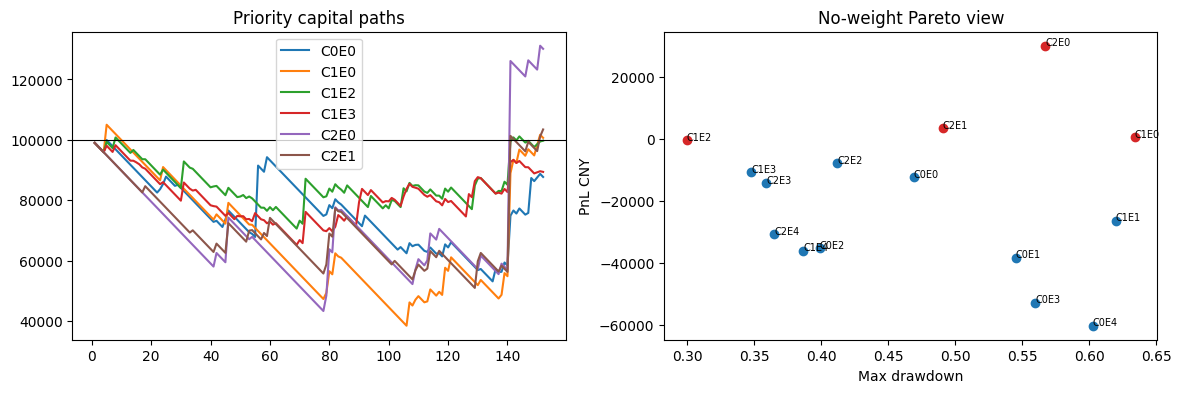

In [13]:
paths=pd.read_csv(OUT/'capital_paths.csv')
fig,axes=plt.subplots(1,2,figsize=(14,4))
keep=['C0E0','C1E0','C1E2','C1E3','C2E0','C2E1']
for cell,g in paths[(paths.scope=='ALL') & paths.cell.isin(keep)].groupby('cell'):
    axes[0].plot(g.issue_order,g.capital_cny,label=cell)
axes[0].axhline(100000,color='black',lw=.8); axes[0].legend(); axes[0].set_title('Priority capital paths')
for _,r in pareto.iterrows():
    axes[1].scatter(r.max_drawdown_fraction,r.pnl_cny,color=('tab:red' if r.pareto else 'tab:blue'))
    axes[1].annotate(r.cell,(r.max_drawdown_fraction,r.pnl_cny),fontsize=7)
axes[1].set_xlabel('Max drawdown'); axes[1].set_ylabel('PnL CNY'); axes[1].set_title('No-weight Pareto view'); plt.show()